# Model Comparison: Real Data, Synthetic Data and the App Decision

## 1. Introduction

This notebook compares saved logistic models and controlled alternatives on the same held-out test set. It asks which model should serve as the app default and whether synthetic training rows improve performance.

**Models:** M1 (saved 70k model), M2 (saved 200k model), M3 (class-weighted logistic regression on real rows only), M4 (70k data with M2's feature list), M5 (linear probability model from notebook 06; reference only), and M6 (M1 without healthcare-access predictors when present).

**Decision rule, stated before results:** choose a model other than M1 only if its precision at matched 85% test recall is at least 0.02 higher than M1's and the 95% paired-bootstrap interval for that precision difference excludes zero. The matched threshold is read from the test curve for descriptive comparison only; it is never used to train or tune an app model. Ties favor the simpler real-data model.

The notebook reads actual features and thresholds from the current bundles because this repo now contains refreshed, shared 14-feature models; the older 16/17-feature claims no longer apply. M1/M2/M5 are loaded, not retrained. M3/M4/M6 train and choose thresholds using training rows only. The held-out test table is opened only after those decisions are fixed.

> **Current metric note:** This notebook records an earlier decision rule based on a 0.02 precision gain. The group has since adopted a recall requirement of at least 85%, with specificity as the main ranking metric and balanced plus approximate 14%-prevalence precision reported. Use `notebooks/10_model_experiments` for the current experiment and final comparison.

## 2. Import Libraries and Configure MariaDB

We import the model, metrics, plotting and database tools. Training tables and bundles are loaded first; the test table stays closed until all training-derived thresholds are selected.

In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sqlalchemy import create_engine
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,brier_score_loss,confusion_matrix,f1_score,
                             precision_recall_curve,precision_score,recall_score,roc_auc_score,roc_curve)
from sklearn.model_selection import StratifiedKFold,cross_val_predict,train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

ROOT=Path("../..").resolve()
TARGET="Diabetes_binary"
RANDOM_STATE=42
TARGET_RECALL=0.85
REAL_PREVALENCE=0.14
NON_BINARY=["BMI","GenHlth","MentHlth","PhysHlth","Age","Education","Income"]
HEALTHCARE_FEATURES={"CholCheck","AnyHealthcare","NoDocbcCost"}
engine=create_engine("mysql+pymysql://root:@localhost:3306/diabetes_final_db")
sns.set_theme(style="whitegrid",context="notebook")
plt.rcParams["figure.dpi"]=110
print("Libraries and MariaDB connection configured; the test table remains unopened.")

Libraries and MariaDB connection configured; the test table remains unopened.


**Interpretation:** MariaDB and the analysis libraries are ready; the held-out test table has not been queried.

## 3. Prepare: Load Training Tables and Current Model Bundles

M1 and M2 use their saved feature lists and thresholds. M3 uses real respondents from the synthetic-training table and class weighting to address class imbalance. We verify current row counts and feature compatibility before fitting controls.

In [2]:
# Load training tables and the saved bundles only; do not read the test table yet.
train_70k=pd.read_sql("SELECT * FROM diabetes_model_train",con=engine)
train_200k=pd.read_sql("SELECT * FROM diabetes_cmu_synth_train",con=engine)
m1_bundle=joblib.load(ROOT/"application/models/logreg_70k.joblib")
m2_bundle=joblib.load(ROOT/"application/models/logreg_200k.joblib")
m5_path=ROOT/"notebooks/06_multilinearreg/linprob_70k.joblib"
m5_bundle=joblib.load(m5_path)
M1_FEATURES=list(m1_bundle["features"]); M2_FEATURES=list(m2_bundle["features"]); M5_FEATURES=list(m5_bundle["features"])
real_rows=train_200k.loc[train_200k["is_synthetic"].eq(0)].drop(columns="is_synthetic").reset_index(drop=True)

# Stop if data sizes differ from the current split or bundle features cannot be found.
if len(train_70k)!=56_155 or len(train_200k)!=200_000 or len(real_rows)!=128_078:
    raise ValueError("Training table sizes differ from the current saved split.")
for name,features,frame in [("M1",M1_FEATURES,train_70k),("M2",M2_FEATURES,train_200k),("M3",M1_FEATURES,real_rows),("M5",M5_FEATURES,train_70k)]:
    absent=[f for f in features if f not in frame.columns]
    if absent: raise ValueError(f"{name} is missing training features: {absent}")
for bundle in [m1_bundle,m2_bundle,m5_bundle]:
    if bundle.get("sklearn_version")!=sklearn.__version__:
        raise RuntimeError(f"Bundle version {bundle.get('sklearn_version')} differs from {sklearn.__version()}.")

inventory=pd.DataFrame([
 {"Model":"M1 — saved 70k real","Training rows":len(train_70k),"Synthetic rows":0,"Features":len(M1_FEATURES),"Threshold":m1_bundle["threshold"],"Feature list":", ".join(M1_FEATURES)},
 {"Model":"M2 — saved 200k real + synthetic","Training rows":len(train_200k),"Synthetic rows":int(train_200k["is_synthetic"].sum()),"Features":len(M2_FEATURES),"Threshold":m2_bundle["threshold"],"Feature list":", ".join(M2_FEATURES)},
 {"Model":"M3 — real-only class-weighted","Training rows":len(real_rows),"Synthetic rows":0,"Features":len(M1_FEATURES),"Threshold":"OOF training estimate","Feature list":", ".join(M1_FEATURES)},
 {"Model":"M4 — 70k with M2 features","Training rows":len(train_70k),"Synthetic rows":0,"Features":len(M2_FEATURES),"Threshold":"OOF unless identical to M1","Feature list":", ".join(M2_FEATURES)},
 {"Model":"M5 — linear probability reference","Training rows":len(train_70k),"Synthetic rows":0,"Features":len(M5_FEATURES),"Threshold":m5_bundle["threshold"],"Feature list":", ".join(M5_FEATURES)},
])
display(inventory.style.hide(axis="index"))
print("Current M1 and M2 features identical:",M1_FEATURES==M2_FEATURES)
print("M3 real-only class counts:",real_rows[TARGET].value_counts().sort_index().to_dict())

Model,Training rows,Synthetic rows,Features,Threshold,Feature list
M1 — saved 70k real,56155,0,14,0.396314,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Income"
M2 — saved 200k real + synthetic,200000,71922,14,0.375532,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Income"
M3 — real-only class-weighted,128078,0,14,OOF training estimate,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Income"
M4 — 70k with M2 features,56155,0,14,OOF unless identical to M1,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Income"
M5 — linear probability reference,56155,0,14,0.423855,"HighBP, HighChol, BMI, Stroke, HeartDiseaseorAttack, Fruits, HvyAlcoholConsump, GenHlth, MentHlth, PhysHlth, DiffWalk, Sex, Age, Income"


Current M1 and M2 features identical: True
M3 real-only class counts: {0: 100000, 1: 28078}


**Interpretation:** Current M1 and M2 bundles each use 14 features and the same saved feature list. M2 uses 71,922 synthetic rows among 200,000 total; the M3 real-only subset has 100,000 no-diabetes and 28,078 diabetes rows.

## 4. Train M3, M4 and M6 on Training Data Only

M3 isolates whether more **real** respondents help: its five-fold thresholds are learned from real-only out-of-fold predictions, with `class_weight="balanced"`. M4 isolates feature effects on 70k rows. M6 removes care-access predictors from M1 when present. Exact duplicate models are reused.

In [3]:
# Create the same scaled logistic-regression pipeline structure used by the saved models.
def make_logreg(cols,class_weight=None):
    scaled=[c for c in cols if c in NON_BINARY]
    prep=ColumnTransformer([("scale",StandardScaler(),scaled)],remainder="passthrough",verbose_feature_names_out=False)
    return Pipeline([("prep",prep),("model",LogisticRegression(C=np.inf,max_iter=2000,class_weight=class_weight))])

def training_oof_threshold(frame,cols,class_weight=None):
    y=frame[TARGET].astype(int)
    cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
    oof=cross_val_predict(make_logreg(cols,class_weight),frame[cols],y,cv=cv,method="predict_proba",n_jobs=-1)[:,1]
    _,recall,thresholds=precision_recall_curve(y,oof)
    valid=thresholds[recall[:-1]>=TARGET_RECALL]
    if not len(valid): raise RuntimeError("No OOF threshold reached the recall goal.")
    return float(valid.max()),oof

# M3 uses only the 128,078 real respondents and balances the classes by weight.
M3_FEATURES=M1_FEATURES.copy()
threshold_m3,oof_m3=training_oof_threshold(real_rows,M3_FEATURES,class_weight="balanced")
m3_model=make_logreg(M3_FEATURES,class_weight="balanced").fit(real_rows[M3_FEATURES],real_rows[TARGET])

# M4 uses 70k data with M2 features. It aliases M1 if the feature lists already match.
M4_FEATURES=M2_FEATURES.copy()
if M4_FEATURES==M1_FEATURES:
    m4_model=m1_bundle["model"]; threshold_m4=float(m1_bundle["threshold"]); m4_alias=True
else:
    threshold_m4,_=training_oof_threshold(train_70k,M4_FEATURES)
    m4_model=make_logreg(M4_FEATURES).fit(train_70k[M4_FEATURES],train_70k[TARGET]); m4_alias=False

# M6 removes the named healthcare-access features only if they are present in M1.
M6_FEATURES=[f for f in M1_FEATURES if f not in HEALTHCARE_FEATURES]
if M6_FEATURES==M1_FEATURES:
    m6_model=m1_bundle["model"]; threshold_m6=float(m1_bundle["threshold"]); m6_alias=True
else:
    threshold_m6,_=training_oof_threshold(train_70k,M6_FEATURES)
    m6_model=make_logreg(M6_FEATURES).fit(train_70k[M6_FEATURES],train_70k[TARGET]); m6_alias=False

models={
 "M1 — saved 70k real":(m1_bundle["model"],M1_FEATURES,float(m1_bundle["threshold"]),False),
 "M2 — saved 200k real + synthetic":(m2_bundle["model"],M2_FEATURES,float(m2_bundle["threshold"]),False),
 "M3 — 128k real only, class-weighted":(m3_model,M3_FEATURES,threshold_m3,False),
 "M4 — 70k with M2 features":(m4_model,M4_FEATURES,threshold_m4,m4_alias),
 "M5 — linear probability reference":(m5_bundle["model"],M5_FEATURES,float(m5_bundle["threshold"]),False),
 "M6 — M1 without healthcare-access features":(m6_model,M6_FEATURES,threshold_m6,m6_alias),
}
decisions=pd.DataFrame([{"Model":name,"Threshold from training":spec[2],"Feature count":len(spec[1]),"Alias of M1":spec[3]} for name,spec in models.items()])
display(decisions.round(4).style.hide(axis="index"))
print(f"M3 OOF threshold: {threshold_m3:.4f}; M4 aliases M1: {m4_alias}; M6 aliases M1: {m6_alias}.")
print("All new thresholds are fixed before opening the held-out test table.")

Model,Threshold from training,Feature count,Alias of M1
M1 — saved 70k real,0.396300,14,False
M2 — saved 200k real + synthetic,0.375500,14,False
"M3 — 128k real only, class-weighted",0.397000,14,False
M4 — 70k with M2 features,0.396300,14,True
M5 — linear probability reference,0.423900,14,False
M6 — M1 without healthcare-access features,0.396300,14,True


M3 OOF threshold: 0.3970; M4 aliases M1: True; M6 aliases M1: True.
All new thresholds are fixed before opening the held-out test table.


**Interpretation:** M3's training-only OOF threshold is 0.3970. M4 aliases M1 because the feature lists match; M6 also aliases M1 because the saved M1 bundle already excludes all three healthcare-access features.

## 5. Evaluate: Open the Shared Held-Out Test Set

All fits and training-derived thresholds are now fixed. We open `diabetes_model_test` for final scoring. Saved bundles determine the feature names and order. M5 raw scores may be outside 0–1; we retain them for thresholding and ranking.

In [4]:
# This is the first time this notebook reads the held-out test table.
test_df=pd.read_sql("SELECT * FROM diabetes_model_test",con=engine)
if len(test_df)!=14_039: raise ValueError(f"Expected 14,039 test rows, found {len(test_df):,}.")
y_test=test_df[TARGET].astype(int).to_numpy()

def score_model(model,cols,frame,is_linear=False):
    if is_linear: return np.asarray(model.predict(frame[cols]),dtype=float)
    return np.asarray(model.predict_proba(frame[cols])[:,1],dtype=float)

scores={}
for name,(model,cols,threshold,alias) in models.items():
    scores[name]=score_model(model,cols,test_df,is_linear=name.startswith("M5"))
print("Test rows loaded for final scoring:",len(test_df))
print("Test class counts:",pd.Series(y_test).value_counts().sort_index().to_dict())
print("M5 raw-score fraction outside [0,1]:",f"{((scores['M5 — linear probability reference']<0)|(scores['M5 — linear probability reference']>1)).mean():.2%}")

Test rows loaded for final scoring: 14039
Test class counts: {0: 7020, 1: 7019}
M5 raw-score fraction outside [0,1]: 4.98%


**Interpretation:** All six models score the same 14,039 test respondents (7,020 no-diabetes and 7,019 diabetes). M5 has 4.98% of raw test predictions outside the valid 0–1 probability range.

## 6. Sanity Check: Reproduce the Current Saved Results

The current repo includes a control-comparison CSV generated with these same bundles and test rows. We compare M1 and M2 AUC and recall at saved/default thresholds with that artifact. This avoids relying on stale figures from the earlier 16/17-feature version.

In [5]:
saved_comparison=pd.read_csv(ROOT/"data/07_cmu+synthetic/diabetes_synthetic_control_comparison.csv")
def saved_row(fragment,point):
    rows=saved_comparison[saved_comparison["Model"].str.contains(fragment,case=False,regex=False)&saved_comparison["Point"].eq(point)]
    if len(rows)!=1: raise ValueError(f"Expected one saved row for {fragment} / {point}; found {len(rows)}.")
    return rows.iloc[0]

sanity_rows=[]
for name,fragment in [("M1 — saved 70k real","70k real balanced"),("M2 — saved 200k real + synthetic","200k real + synthetic")]:
    raw=scores[name]; chosen=models[name][2]
    for point,cut in [("Chosen threshold",chosen),("Default (0.50)",0.5)]:
        pred=(raw>=cut).astype(int); saved=saved_row(fragment,point)
        rec=recall_score(y_test,pred); auc=roc_auc_score(y_test,raw)
        sanity_rows.append({"Model":name,"Point":point,"Recomputed recall":rec,"Saved recall":saved["Recall (sensitivity)"],
                            "Recomputed AUC":auc,"Saved AUC":saved["ROC AUC"],
                            "Matches":np.isclose(rec,saved["Recall (sensitivity)"],atol=1e-10) and np.isclose(auc,saved["ROC AUC"],atol=1e-10)})
sanity=pd.DataFrame(sanity_rows)
display(sanity.round(6).style.hide(axis="index"))
if not sanity["Matches"].all(): raise RuntimeError("Current model scores do not reproduce the saved comparison CSV.")
print("M1 and M2 scores reproduce the saved test metrics.")

Model,Point,Recomputed recall,Saved recall,Recomputed AUC,Saved AUC,Matches
M1 — saved 70k real,Chosen threshold,0.850121,0.850121,0.800309,0.800309,True
M1 — saved 70k real,Default (0.50),0.745975,0.745975,0.800309,0.800309,True
M2 — saved 200k real + synthetic,Chosen threshold,0.848696,0.848696,0.799885,0.799885,True
M2 — saved 200k real + synthetic,Default (0.50),0.728594,0.728594,0.799885,0.799885,True


M1 and M2 scores reproduce the saved test metrics.


**Interpretation:** Recomputed M1 and M2 recall/AUC match the current saved comparison artifact at both selected and default thresholds, so the current bundles and test table are aligned.

## 7. Test Results at Each Model's Own Threshold and at 0.50

Recall is reported with specificity and false alarms because finding more cases may flag more people without diabetes. Balanced-test precision is optimistic, so the table also estimates precision and share flagged at 14% prevalence.

In [6]:
def evaluate_scores(y,raw,threshold,is_linear=False):
    y=np.asarray(y); raw=np.asarray(raw); pred=(raw>=threshold).astype(int)
    prob=np.clip(raw,0,1) if is_linear else raw
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    rec=tp/(tp+fn); spec=tn/(tn+fp)
    share=rec*REAL_PREVALENCE+(1-spec)*(1-REAL_PREVALENCE)
    return {"Threshold":float(threshold),"Accuracy":accuracy_score(y,pred),"Recall (sensitivity)":rec,
            "Specificity":spec,"Precision":precision_score(y,pred,zero_division=0),"F1":f1_score(y,pred),
            "ROC AUC":roc_auc_score(y,raw),"Brier score":brier_score_loss(y,prob),
            "False negatives":int(fn),"False positives":int(fp),
            "Precision @ 14%":rec*REAL_PREVALENCE/share,"Share flagged @ 14%":share}

result_rows=[]
for name,raw in scores.items():
    for point,cut in [("Own threshold",models[name][2]),("Default (0.50)",0.5)]:
        result_rows.append({"Model":name,"Point":point,**evaluate_scores(y_test,raw,cut,name.startswith("M5"))})
results=pd.DataFrame(result_rows)
display(results.round(4).style.hide(axis="index"))
print("Own thresholds are from saved bundles or training-only OOF estimates; default threshold is 0.50.")

Model,Point,Threshold,Accuracy,Recall (sensitivity),Specificity,Precision,F1,ROC AUC,Brier score,False negatives,False positives,Precision @ 14%,Share flagged @ 14%
M1 — saved 70k real,Own threshold,0.396300,0.726100,0.850100,0.602100,0.681200,0.756300,0.800300,0.181700,1052,2793,0.258100,0.461200
M1 — saved 70k real,Default (0.50),0.500000,0.727700,0.746000,0.709400,0.719600,0.732600,0.800300,0.181700,1783,2040,0.294700,0.354400
M2 — saved 200k real + synthetic,Own threshold,0.375500,0.724100,0.848700,0.599400,0.679300,0.754600,0.799900,0.182400,1062,2812,0.256500,0.463300
M2 — saved 200k real + synthetic,Default (0.50),0.500000,0.726000,0.728600,0.723400,0.724800,0.726700,0.799900,0.182400,1905,1942,0.300100,0.339900
"M3 — 128k real only, class-weighted",Own threshold,0.397000,0.726400,0.848800,0.604000,0.681800,0.756200,0.800300,0.181700,1061,2780,0.258700,0.459400
"M3 — 128k real only, class-weighted",Default (0.50),0.500000,0.727400,0.745300,0.709500,0.719500,0.732200,0.800300,0.181700,1788,2039,0.294600,0.354100
M4 — 70k with M2 features,Own threshold,0.396300,0.726100,0.850100,0.602100,0.681200,0.756300,0.800300,0.181700,1052,2793,0.258100,0.461200
M4 — 70k with M2 features,Default (0.50),0.500000,0.727700,0.746000,0.709400,0.719600,0.732600,0.800300,0.181700,1783,2040,0.294700,0.354400
M5 — linear probability reference,Own threshold,0.423900,0.724500,0.850700,0.598300,0.679200,0.755300,0.799400,0.183100,1048,2820,0.256400,0.464600
M5 — linear probability reference,Default (0.50),0.500000,0.726800,0.753000,0.700600,0.715400,0.733700,0.799400,0.183100,1734,2102,0.290500,0.362900


Own thresholds are from saved bundles or training-only OOF estimates; default threshold is 0.50.


**Interpretation:** At their selected cutoffs, M1 reaches 0.8501 recall and 0.6021 specificity; M2 reaches 0.8487 recall and 0.5994 specificity. Their test AUCs are 0.8003 and 0.7999, respectively. M3 is very similar: 0.8488 recall, 0.6040 specificity and 0.8003 AUC.

### Balanced-Test Precision and Recall by Model

This comparison uses each model's **own saved or training-derived threshold** and the same balanced held-out test respondents. Precision here is therefore **balanced-test precision**, not expected real-world precision. This is a descriptive comparison of the trade-off; it does not change any threshold or select a model. The agreed screening requirement is at least 85% Recall, with Specificity used to compare models that meet it.

In [ ]:
# Compare balanced-test Recall and Precision for all six models at their own thresholds.
# These thresholds are saved in the bundles or derived from training-only out-of-fold predictions.
own_threshold_results = results.loc[results["Point"].eq("Own threshold")].copy()

# Keep the M1-to-M6 order so the table and chart are easy to compare.
model_order = [name for name in models]
own_threshold_results["Model"] = pd.Categorical(
    own_threshold_results["Model"], categories=model_order, ordered=True
)
own_threshold_results = own_threshold_results.sort_values("Model").copy()
own_threshold_results["Model ID"] = own_threshold_results["Model"].astype(str).str.extract(r"^(M[1-6])")

precision_recall_summary = own_threshold_results[[
    "Model ID", "Model", "Threshold", "Recall (sensitivity)", "Precision"
]].rename(columns={"Recall (sensitivity)": "Recall", "Precision": "Balanced-test precision"})
display(precision_recall_summary[["Model ID", "Threshold", "Recall", "Balanced-test precision"]]
        .round(4).style.hide(axis="index"))

# A paired horizontal bar chart keeps all models visible and uses the same 0-to-1 scale.
y_positions = np.arange(len(precision_recall_summary))
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
chart_metrics = [
    ("Recall", "#E45756", "Recall (sensitivity)"),
    ("Balanced-test precision", "#4C78A8", "Balanced-test precision"),
]
for ax, (column, color, title) in zip(axes, chart_metrics):
    bars = ax.barh(y_positions, precision_recall_summary[column], color=color)
    ax.set_yticks(y_positions)
    ax.set_yticklabels(precision_recall_summary["Model ID"])
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("Score")
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.25)
    ax.bar_label(bars, fmt="%.3f", padding=3)
axes[0].axvline(TARGET_RECALL, color="#222222", linestyle="--", linewidth=1,
                label="85% Recall requirement")
axes[0].legend(loc="lower right")
fig.suptitle("Balanced-test Recall and Precision at each model's own threshold")
fig.text(0.5, 0.01, "All models use the same held-out respondents; precision reflects the artificial 50/50 test balance.",
         ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()
print("Chart includes M1 through M6 at their saved or training-derived thresholds.")

**Interpretation:** The chart compares how many diagnosed respondents each model catches (Recall) with how many flagged respondents are actually labeled as diagnosed in this balanced test set (precision). M1 and M2 are very close; M3 is also similar. M4 and M6 overlap M1 because, with the current feature bundles, they are exact aliases. Use the 85% Recall line as the first screen, then compare Specificity among models that meet the requirement; do not choose by balanced-test precision alone because it is optimistic for the real population.

## 8. Matched-Recall Comparison (Descriptive Only)

To compare precision at similar case capture, we find the test-score cutoff that reaches 85% recall. This test-derived threshold is descriptive only; it is never used to fit or tune an app model.

In [7]:
def descriptive_threshold_at_recall(y,raw,goal=TARGET_RECALL):
    _,rec,thresholds=precision_recall_curve(y,raw)
    valid=thresholds[rec[:-1]>=goal]
    return float(valid.max()) if len(valid) else float(np.min(raw))

matched_rows=[]; matched_thresholds={}
for name,raw in scores.items():
    cut=descriptive_threshold_at_recall(y_test,raw)
    matched_thresholds[name]=cut
    m=evaluate_scores(y_test,raw,cut,name.startswith("M5"))
    matched_rows.append({"Model":name,"Test-derived threshold (descriptive)":cut,"Recall":m["Recall (sensitivity)"],
                         "Specificity":m["Specificity"],"Precision (balanced test)":m["Precision"],
                         "Precision @ 14%":m["Precision @ 14%"],"Share flagged @ 14%":m["Share flagged @ 14%"]})
matched=pd.DataFrame(matched_rows)
display(matched.round(4).style.hide(axis="index"))
print("These test-derived cutoffs are descriptive and do not change any saved model threshold.")

Model,Test-derived threshold (descriptive),Recall,Specificity,Precision (balanced test),Precision @ 14%,Share flagged @ 14%
M1 — saved 70k real,0.396400,0.850100,0.602100,0.681200,0.258100,0.461200
M2 — saved 200k real + synthetic,0.374200,0.850100,0.598100,0.679000,0.256200,0.464600
"M3 — 128k real only, class-weighted",0.395300,0.850100,0.601900,0.681000,0.257900,0.461400
M4 — 70k with M2 features,0.396400,0.850100,0.602100,0.681200,0.258100,0.461200
M5 — linear probability reference,0.424500,0.850100,0.599000,0.679500,0.256600,0.463900
M6 — M1 without healthcare-access features,0.396400,0.850100,0.602100,0.681200,0.258100,0.461200


These test-derived cutoffs are descriptive and do not change any saved model threshold.


**Interpretation:** At descriptive matched recall, M1 precision is 0.6812 and M2 is 0.6790; M2 flags a slightly larger share at the assumed 14% prevalence (46.46% vs. 46.12%). These test-derived cutoffs are not deployment thresholds.

## 9. ROC and Calibration Curves

ROC curves compare model ranking over thresholds. Calibration curves compare predicted probability with observed positive frequency. For M5, use raw values for ROC and clipped values for calibration because probabilities must be between 0 and 1.

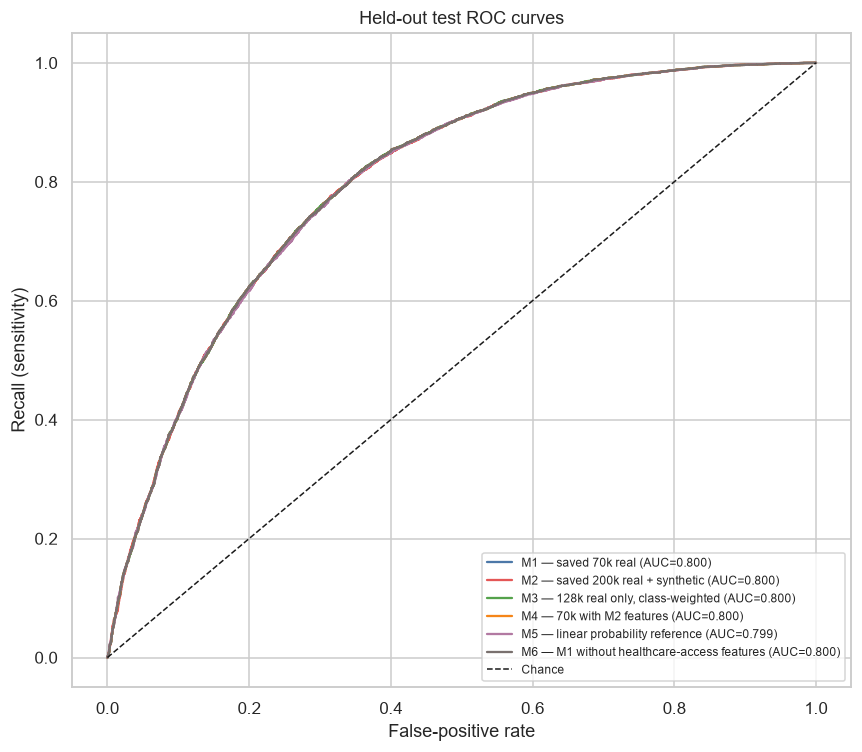

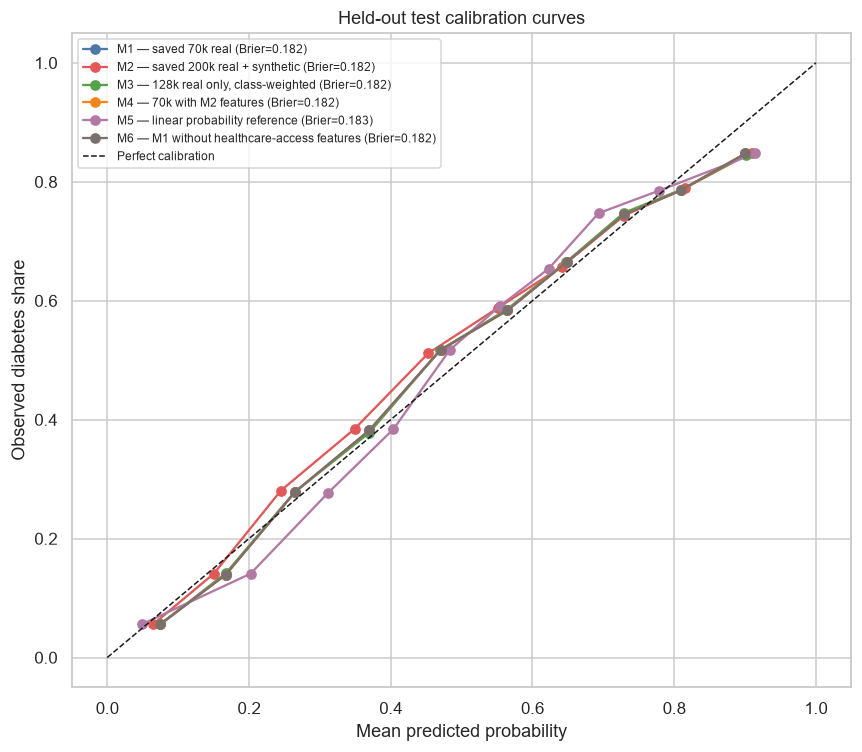

Every line uses the same held-out respondents.


In [8]:
colors={"M1 — saved 70k real":"#4C78A8","M2 — saved 200k real + synthetic":"#E45756",
        "M3 — 128k real only, class-weighted":"#54A24B","M4 — 70k with M2 features":"#F58518",
        "M5 — linear probability reference":"#B279A2","M6 — M1 without healthcare-access features":"#79706E"}
# Plot all ROC curves on the same held-out test respondents.
fig,ax=plt.subplots(figsize=(8,7))
for name,raw in scores.items():
    fpr,tpr,_=roc_curve(y_test,raw)
    ax.plot(fpr,tpr,color=colors[name],label=f"{name} (AUC={roc_auc_score(y_test,raw):.3f})")
ax.plot([0,1],[0,1],"k--",lw=1,label="Chance")
ax.set(title="Held-out test ROC curves",xlabel="False-positive rate",ylabel="Recall (sensitivity)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

# Plot calibration with ten equal-count probability groups.
fig,ax=plt.subplots(figsize=(8,7))
for name,raw in scores.items():
    p=np.clip(raw,0,1) if name.startswith("M5") else raw
    observed,mean_score=calibration_curve(y_test,p,n_bins=10,strategy="quantile")
    ax.plot(mean_score,observed,marker="o",color=colors[name],label=f"{name} (Brier={brier_score_loss(y_test,p):.3f})")
ax.plot([0,1],[0,1],"k--",lw=1,label="Perfect calibration")
ax.set(title="Held-out test calibration curves",xlabel="Mean predicted probability",ylabel="Observed diabetes share")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print("Every line uses the same held-out respondents.")

**Interpretation:** M1 and M2 ROC curves are nearly overlapping (AUC 0.8003 vs. 0.7999). Their Brier scores are 0.1817 and 0.1824; M1 is slightly better calibrated overall on this test set.

## 10. Uncertainty: Paired Bootstrap

The paired bootstrap resamples the same test respondents for every model. We calculate 95% percentile intervals for AUC, Recall and Specificity at the fixed training-derived thresholds, and precision at matched 85% recall. For the last metric, the matched threshold is recomputed within each resample.

In [9]:
rng=np.random.default_rng(RANDOM_STATE)
y_arr=np.asarray(y_test); N_BOOT=1000
metrics_names=["ROC AUC","Recall at chosen threshold","Specificity at chosen threshold","Precision at matched recall"]
boot_values={name:{metric:[] for metric in metrics_names} for name in models}
boot_diffs={name:{metric:[] for metric in metrics_names} for name in models if name!="M1 — saved 70k real"}
m1_name="M1 — saved 70k real"

def bootstrap_matched_cut(y,raw,goal=TARGET_RECALL):
    # The lower quantile ensures at least the target share of positive scores are included.
    return float(np.quantile(np.asarray(raw)[np.asarray(y)==1],1-goal,method="lower"))

for b in range(N_BOOT):
    idx=rng.integers(0,len(y_arr),len(y_arr)); yb=y_arr[idx]; current={}
    for name,all_scores in scores.items():
        raw=np.asarray(all_scores)[idx]; cut=models[name][2]; pred=(raw>=cut).astype(int)
        tn,fp,fn,tp=confusion_matrix(yb,pred,labels=[0,1]).ravel()
        rec=tp/(tp+fn); spec=tn/(tn+fp)
        auc=roc_auc_score(yb,raw)
        matched_cut=bootstrap_matched_cut(yb,raw)
        matched_prec=precision_score(yb,(raw>=matched_cut).astype(int),zero_division=0)
        current[name]={"ROC AUC":auc,"Recall at chosen threshold":rec,
                       "Specificity at chosen threshold":spec,"Precision at matched recall":matched_prec}
        for metric,value in current[name].items(): boot_values[name][metric].append(value)
    for name in boot_diffs:
        for metric in metrics_names: boot_diffs[name][metric].append(current[name][metric]-current[m1_name][metric])

def ci95(values): return np.nanpercentile(np.asarray(values,dtype=float),[2.5,97.5])
boot_rows=[]
for name,metrics_dict in boot_values.items():
    for metric,values in metrics_dict.items():
        lo,hi=ci95(values); boot_rows.append({"Quantity":name,"Metric":metric,"95% CI lower":lo,"95% CI upper":hi})
for name,metrics_dict in boot_diffs.items():
    for metric,values in metrics_dict.items():
        lo,hi=ci95(values); boot_rows.append({"Quantity":f"{name} minus M1","Metric":metric,"95% CI lower":lo,"95% CI upper":hi})
bootstrap_summary=pd.DataFrame(boot_rows)
display(bootstrap_summary.round(4).style.hide(axis="index"))
print(f"Paired bootstrap completed: {N_BOOT:,} resamples, seed {RANDOM_STATE}.")

Quantity,Metric,95% CI lower,95% CI upper
M1 — saved 70k real,ROC AUC,0.792900,0.807900
M1 — saved 70k real,Recall at chosen threshold,0.841400,0.858400
M1 — saved 70k real,Specificity at chosen threshold,0.591100,0.614200
M1 — saved 70k real,Precision at matched recall,0.668800,0.692600
M2 — saved 200k real + synthetic,ROC AUC,0.792400,0.807400
M2 — saved 200k real + synthetic,Recall at chosen threshold,0.840100,0.857300
M2 — saved 200k real + synthetic,Specificity at chosen threshold,0.587800,0.611300
M2 — saved 200k real + synthetic,Precision at matched recall,0.666900,0.690700
"M3 — 128k real only, class-weighted",ROC AUC,0.793000,0.808000
"M3 — 128k real only, class-weighted",Recall at chosen threshold,0.840000,0.857500


Paired bootstrap completed: 1,000 resamples, seed 42.


**Interpretation:** The paired 95% interval for M2 minus M1 precision at matched recall is −0.0052 to 0.0009, which includes zero. The intervals for the AUC and chosen-threshold metrics also overlap heavily; the small differences are not clear evidence of a real advantage.

## 11. Synthetic-Data Control and Fidelity

M1 vs. M4 holds training data fixed while checking features; M4 vs. M2 separates the larger synthetic training set. M3 asks whether class-weighting more real respondents is sufficient. A separate random forest tests whether real and synthetic diabetes rows are distinguishable, using only training rows.

In [10]:
# Compare controlled logistic models at their own thresholds.
control_names=["M1 — saved 70k real","M4 — 70k with M2 features","M2 — saved 200k real + synthetic","M3 — 128k real only, class-weighted"]
control_table=results[results.Model.isin(control_names)&results.Point.eq("Own threshold")][
    ["Model","Threshold","Recall (sensitivity)","Specificity","Precision","ROC AUC","False positives"]]
display(control_table.round(4).style.hide(axis="index"))
print("M4 is an exact M1 alias when feature lists match:",m4_alias)

# Use a stratified training-only holdout to see how easily synthetic status can be detected.
all_features=[c for c in train_200k.columns if c not in [TARGET,"is_synthetic"]]
real_diabetes=train_200k[(train_200k.is_synthetic==0)&(train_200k[TARGET]==1)]
synthetic_diabetes=train_200k[train_200k.is_synthetic==1]
n_audit=min(len(real_diabetes),len(synthetic_diabetes))
audit_real=real_diabetes.sample(n=n_audit,random_state=RANDOM_STATE)
audit_synthetic=synthetic_diabetes.sample(n=n_audit,random_state=RANDOM_STATE)
audit=pd.concat([audit_real,audit_synthetic],ignore_index=True)
audit_y=audit.is_synthetic.astype(int)
x_fit,x_hold,y_fit,y_hold=train_test_split(audit[all_features],audit_y,test_size=0.25,
                                          random_state=RANDOM_STATE,stratify=audit_y)
rf=RandomForestClassifier(n_estimators=150,min_samples_leaf=5,class_weight="balanced",
                          random_state=RANDOM_STATE,n_jobs=-1).fit(x_fit,y_fit)
synthetic_auc=roc_auc_score(y_hold,rf.predict_proba(x_hold)[:,1])

fidelity_features=[c for c in ["MentHlth","PhysHlth","DiffWalk","HvyAlcoholConsump"] if c in train_200k]
fidelity=pd.DataFrame([{"Feature":f,"Real diabetes training mean":real_diabetes[f].mean(),
                        "Synthetic diabetes mean":synthetic_diabetes[f].mean()} for f in fidelity_features])
display(fidelity.round(4).style.hide(axis="index"))
print(f"Training-only random-forest AUC for synthetic status: {synthetic_auc:.4f}; audit rows per class: {n_audit:,}.")

Model,Threshold,Recall (sensitivity),Specificity,Precision,ROC AUC,False positives
M1 — saved 70k real,0.396300,0.850100,0.602100,0.681200,0.800300,2793
M2 — saved 200k real + synthetic,0.375500,0.848700,0.599400,0.679300,0.799900,2812
"M3 — 128k real only, class-weighted",0.397000,0.848800,0.604000,0.681800,0.800300,2780
M4 — 70k with M2 features,0.396300,0.850100,0.602100,0.681200,0.800300,2793


M4 is an exact M1 alias when feature lists match: True


Feature,Real diabetes training mean,Synthetic diabetes mean
MentHlth,4.497000,5.300300
PhysHlth,8.002100,9.178200
DiffWalk,0.374200,0.421700
HvyAlcoholConsump,0.023200,0.017000


Training-only random-forest AUC for synthetic status: 0.6048; audit rows per class: 28,078.


**Interpretation:** The real-only class-weighted M3 control slightly exceeds M2 on this test (AUC 0.8003 vs. 0.7999; selected-threshold recall 0.8488 vs. 0.8487). A training-only random forest distinguishes synthetic status with AUC 0.6048, and synthetic rows have somewhat higher mean MentHlth, PhysHlth and DiffWalk and lower HvyAlcoholConsump than real diabetes rows.

## 12. Healthcare-Access Check

We compare M1/M2 recall and share flagged among test respondents with `CholCheck = 0` and `1`. For a what-if check, we select the highest-scoring training respondent and toggle only `CholCheck`. If the saved bundle excludes that feature, its score cannot change because of this answer. This diagnostic is not used to tune a threshold.

In [11]:
# Subgroup results reveal whether observed test groups behave differently at the saved cutoffs.
health_rows=[]
for name in ["M1 — saved 70k real","M2 — saved 200k real + synthetic"]:
    raw=scores[name]; cut=models[name][2]
    for value in sorted(test_df["CholCheck"].dropna().unique()):
        mask=test_df["CholCheck"].to_numpy()==value
        yg=y_test[mask]; pred=(raw[mask]>=cut).astype(int)
        health_rows.append({"Model":name,"CholCheck":int(value),"Rows":int(mask.sum()),
                            "Recall":recall_score(yg,pred,zero_division=0),"Share flagged":pred.mean()})
health_groups=pd.DataFrame(health_rows)
display(health_groups.round(4).style.hide(axis="index"))

# Choose a reproducible high-score profile from training respondents, not from the test set.
train_score_m1=m1_bundle["model"].predict_proba(train_70k[M1_FEATURES])[:,1]
example=train_70k.iloc[int(np.argmax(train_score_m1))].drop(labels=[TARGET]).copy()
what_if=[]
for name in ["M1 — saved 70k real","M2 — saved 200k real + synthetic"]:
    model,cols,cut,_=models[name]
    for answer in [0,1]:
        profile=example.copy(); profile["CholCheck"]=answer
        value=float(model.predict_proba(pd.DataFrame([profile])[cols])[0,1])
        what_if.append({"Model":name,"CholCheck answer":answer,"Score":value,"Flagged":value>=cut,"Saved threshold":cut})
what_if=pd.DataFrame(what_if)
display(what_if.round(4).style.hide(axis="index"))

m1_auc=roc_auc_score(y_test,scores["M1 — saved 70k real"])
m6_auc=roc_auc_score(y_test,scores["M6 — M1 without healthcare-access features"])
m1_recall=evaluate_scores(y_test,scores["M1 — saved 70k real"],models["M1 — saved 70k real"][2])["Recall (sensitivity)"]
m6_recall=evaluate_scores(y_test,scores["M6 — M1 without healthcare-access features"],models["M6 — M1 without healthcare-access features"][2])["Recall (sensitivity)"]
print("M6 features equal M1:",M6_FEATURES==M1_FEATURES)
print(f"M6 minus M1: test AUC {m6_auc-m1_auc:+.6f}; recall {m6_recall-m1_recall:+.6f}.")

Model,CholCheck,Rows,Recall,Share flagged
M1 — saved 70k real,0,356,0.944400,0.264000
M1 — saved 70k real,1,13683,0.849600,0.633300
M2 — saved 200k real + synthetic,0,356,0.944400,0.269700
M2 — saved 200k real + synthetic,1,13683,0.848200,0.633900


Model,CholCheck answer,Score,Flagged,Saved threshold
M1 — saved 70k real,0,0.998400,True,0.396300
M1 — saved 70k real,1,0.998400,True,0.396300
M2 — saved 200k real + synthetic,0,0.998800,True,0.375500
M2 — saved 200k real + synthetic,1,0.998800,True,0.375500


M6 features equal M1: True
M6 minus M1: test AUC +0.000000; recall +0.000000.


**Interpretation:** The CholCheck=0 subgroup is small (356 people) and has a higher observed recall than the CholCheck=1 group for both models. However, changing CholCheck in the selected high-scoring training profile leaves both scores unchanged because neither bundle uses that feature. M6 is identical to M1, so its test AUC and recall cost is zero.

## 13. Odds Ratios for Shared Logistic Features

For logistic regression, an odds ratio is `exp(coefficient)`: for binary features it compares 1 with 0; for standardized numeric features it is per standard deviation. These are conditional associations, not causes. We compare features shared by M1, M2 and M3.

Feature,M1: 70k real,M2: 200k + synthetic,M3: real-only class-weighted
Age,1.531000,1.503000,1.584000
BMI,1.652000,1.720000,1.614000
DiffWalk,1.131000,1.163000,1.135000
Fruits,0.954000,0.960000,0.968000
GenHlth,1.837000,1.912000,1.808000
HeartDiseaseorAttack,1.255000,1.202000,1.249000
HighBP,2.110000,2.141000,2.091000
HighChol,1.824000,1.830000,1.793000
HvyAlcoholConsump,0.455000,0.376000,0.444000
Income,0.909000,0.872000,0.906000


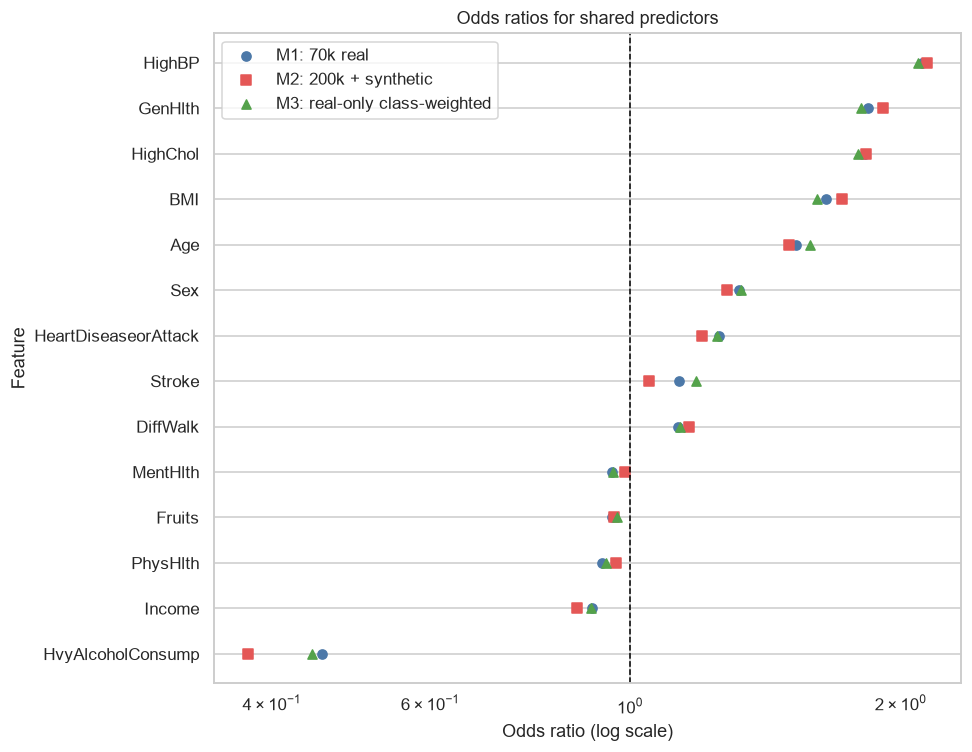

The plot shows adjusted associations, not causal effects.


In [12]:
def odds_ratio_frame(model,cols,label):
    names=list(model.named_steps["prep"].get_feature_names_out())
    values=np.exp(model.named_steps["model"].coef_[0])
    return pd.DataFrame({"Model":label,"Feature":names,"Odds ratio":values})

or_all=pd.concat([odds_ratio_frame(m1_bundle["model"],M1_FEATURES,"M1: 70k real"),
                  odds_ratio_frame(m2_bundle["model"],M2_FEATURES,"M2: 200k + synthetic"),
                  odds_ratio_frame(m3_model,M3_FEATURES,"M3: real-only class-weighted")],ignore_index=True)
shared_features=sorted(set(M1_FEATURES)&set(M2_FEATURES)&set(M3_FEATURES))
or_all=or_all[or_all.Feature.isin(shared_features)]
or_table=or_all.pivot(index="Feature",columns="Model",values="Odds ratio").round(3).reset_index()
display(or_table.style.hide(axis="index"))

# A log axis makes odds ratios above and below one easier to compare.
fig,ax=plt.subplots(figsize=(9,7))
order=or_all[or_all.Model.eq("M1: 70k real")].sort_values("Odds ratio").Feature.tolist()
for label,color,marker in [("M1: 70k real","#4C78A8","o"),("M2: 200k + synthetic","#E45756","s"),("M3: real-only class-weighted","#54A24B","^")]:
    values=or_all[or_all.Model.eq(label)].set_index("Feature").reindex(order)
    ax.scatter(values["Odds ratio"],order,color=color,marker=marker,label=label)
ax.axvline(1,color="black",linestyle="--",linewidth=1); ax.set_xscale("log")
ax.set(title="Odds ratios for shared predictors",xlabel="Odds ratio (log scale)",ylabel="Feature")
ax.legend(); plt.tight_layout(); plt.show()
print("The plot shows adjusted associations, not causal effects.")

**Interpretation:** HighBP has the largest odds ratio in each model (about 2.09–2.14), and odds ratios are broadly similar across the three real/synthetic training approaches. HvyAlcoholConsump is below one in all three; this must not be interpreted as protective or causal.

## 14. Subgroup Check: Sex and Age

We report group sizes, recall and specificity for M1/M2 at their saved thresholds. Age codes 1–5 represent ages 18–44, 6–9 represent 45–64, and 10–13 represent 65 or older. These comparisons are descriptive and group sizes matter.

In [13]:
age_code=test_df["Age"].to_numpy()
age_group=np.select([age_code<=5,age_code<=9],["18-44","45-64"],default="65+")
subgroup_data=test_df[[TARGET,"Sex"]].copy(); subgroup_data["Age group"]=age_group
subgroup_rows=[]
for name in ["M1 — saved 70k real","M2 — saved 200k real + synthetic"]:
    raw=scores[name]; pred=(raw>=models[name][2]).astype(int)
    for column in ["Sex","Age group"]:
        for group in subgroup_data[column].drop_duplicates().tolist():
            mask=subgroup_data[column].to_numpy()==group; yg=y_test[mask]; pg=pred[mask]
            tn,fp,fn,tp=confusion_matrix(yg,pg,labels=[0,1]).ravel()
            subgroup_rows.append({"Model":name,"Grouping":column,"Group":group,"Rows":int(mask.sum()),
                                  "Recall":tp/(tp+fn) if tp+fn else np.nan,
                                  "Specificity":tn/(tn+fp) if tn+fp else np.nan})
subgroups=pd.DataFrame(subgroup_rows)
display(subgroups.round(4).style.hide(axis="index"))
print("Age groups are formed from BRFSS 5-year age-category codes.")

Model,Grouping,Group,Rows,Recall,Specificity
M1 — saved 70k real,Sex,1,6395,0.860500,0.544300
M1 — saved 70k real,Sex,0,7644,0.840800,0.647100
M1 — saved 70k real,Age group,45-64,5977,0.813300,0.624600
M1 — saved 70k real,Age group,65+,5909,0.916000,0.359400
M1 — saved 70k real,Age group,18-44,2153,0.567400,0.890100
M2 — saved 200k real + synthetic,Sex,1,6395,0.849000,0.557300
M2 — saved 200k real + synthetic,Sex,0,7644,0.848400,0.632200
M2 — saved 200k real + synthetic,Age group,45-64,5977,0.817300,0.619000
M2 — saved 200k real + synthetic,Age group,65+,5909,0.907200,0.371600
M2 — saved 200k real + synthetic,Age group,18-44,2153,0.589100,0.872400


Age groups are formed from BRFSS 5-year age-category codes.


**Interpretation:** M1 and M2 subgroup recalls are both lower for ages 18–44 (0.567 and 0.589) and higher for 65+ (0.916 and 0.907), while specificity goes the opposite way. Sex-specific rates also differ; interpret them with the displayed subgroup sizes.

## 15. Practical Factors

The app also needs a small question set, clear interpretation and dependable behavior. This table summarizes practical trade-offs alongside the statistical comparison.

In [14]:
practical=pd.DataFrame([
 {"Model":"M1 — saved 70k real","Training data":"56,155 real balanced rows","Synthetic rows":"No","Interpretability":"High; logistic regression","Main practical risk":"Sampling limitations","App questions":len(M1_FEATURES)},
 {"Model":"M2 — saved 200k real + synthetic","Training data":"128,078 real + 71,922 synthetic","Synthetic rows":"Yes","Interpretability":"High; logistic regression","Main practical risk":"Synthetic artifacts; no measured gain here","App questions":len(M2_FEATURES)},
 {"Model":"M3 — 128k real only, class-weighted","Training data":"128,078 real rows","Synthetic rows":"No","Interpretability":"High; logistic regression","Main practical risk":"Not saved as an app bundle","App questions":len(M3_FEATURES)},
 {"Model":"M4 — 70k with M2 features","Training data":"56,155 real balanced rows","Synthetic rows":"No","Interpretability":"High; logistic regression","Main practical risk":"Not separately saved if same as M1","App questions":len(M4_FEATURES)},
 {"Model":"M5 — linear probability reference","Training data":"56,155 real balanced rows","Synthetic rows":"No","Interpretability":"High; linear coefficients","Main practical risk":"Raw scores can fall outside 0–1","App questions":len(M5_FEATURES)},
 {"Model":"M6 — M1 without access features","Training data":"56,155 real balanced rows","Synthetic rows":"No","Interpretability":"High; logistic regression","Main practical risk":"Not separately saved if same as M1","App questions":len(M6_FEATURES)},
])
display(practical.style.hide(axis="index"))
print("The Streamlit app asks only for features recorded in the selected saved bundle.")

Model,Training data,Synthetic rows,Interpretability,Main practical risk,App questions
M1 — saved 70k real,"56,155 real balanced rows",No,High; logistic regression,Sampling limitations,14
M2 — saved 200k real + synthetic,"128,078 real + 71,922 synthetic",Yes,High; logistic regression,Synthetic artifacts; no measured gain here,14
"M3 — 128k real only, class-weighted","128,078 real rows",No,High; logistic regression,Not saved as an app bundle,14
M4 — 70k with M2 features,"56,155 real balanced rows",No,High; logistic regression,Not separately saved if same as M1,14
M5 — linear probability reference,"56,155 real balanced rows",No,High; linear coefficients,Raw scores can fall outside 0–1,14
M6 — M1 without access features,"56,155 real balanced rows",No,High; logistic regression,Not separately saved if same as M1,14


The Streamlit app asks only for features recorded in the selected saved bundle.


**Interpretation:** All models ask 14 app questions. M1 and M2 are the currently saved app bundles; M3 is a useful real-only control but is not saved as an app bundle, and M5 remains a linear-model reference.

## 16. Apply the Prewritten Model-Selection Rule

The precision difference must be at least 0.02 at matched 85% recall, and its paired-bootstrap interval must exclude zero. M3, M4, M5 and M6 are controls or references, not saved app bundles in this repo; only M2 is an available alternative to M1 for this decision. Do not change `DEFAULT_MODEL` based on an unsaved control model.

In [15]:
# Use the paired-bootstrap interval for the difference in balanced-test precision at matched recall.
matched_by_name=matched.set_index("Model")
boot_by_key=bootstrap_summary.set_index(["Quantity","Metric"])
comparison_rows=[]
for name in ["M2 — saved 200k real + synthetic","M3 — 128k real only, class-weighted",
             "M4 — 70k with M2 features","M5 — linear probability reference",
             "M6 — M1 without healthcare-access features"]:
    delta=float(matched_by_name.loc[name,"Precision (balanced test)"]-
                matched_by_name.loc[m1_name,"Precision (balanced test)"])
    ci=boot_by_key.loc[(f"{name} minus M1","Precision at matched recall")]
    excludes_zero=(ci["95% CI lower"]>0) or (ci["95% CI upper"]<0)
    comparison_rows.append({"Candidate":name,"Precision difference vs M1":delta,
                            "Paired 95% CI lower":ci["95% CI lower"],"Paired 95% CI upper":ci["95% CI upper"],
                            "Meets +0.02 and CI rule":delta>=0.02 and excludes_zero,
                            "Saved app bundle available":name.startswith("M2")})
decision_table=pd.DataFrame(comparison_rows)
display(decision_table.round(4).style.hide(axis="index"))

# The only currently saved app alternative to M1 is M2; controls are not exported to application/models.
m2_qualifies=bool(decision_table.loc[decision_table.Candidate.eq("M2 — saved 200k real + synthetic"),"Meets +0.02 and CI rule"].iloc[0])
recommended="M2 — saved 200k real + synthetic" if m2_qualifies else "M1 — saved 70k real"
print("Decision under the prewritten rule among saved app bundles:",recommended)
print("Set DEFAULT_MODEL to", "logreg_200k.joblib" if m2_qualifies else "logreg_70k.joblib")

Candidate,Precision difference vs M1,Paired 95% CI lower,Paired 95% CI upper,Meets +0.02 and CI rule,Saved app bundle available
M2 — saved 200k real + synthetic,-0.002200,-0.005200,0.000900,False,True
"M3 — 128k real only, class-weighted",-0.000200,-0.001000,0.001900,False,False
M4 — 70k with M2 features,0.000000,0.000000,0.000000,False,False
M5 — linear probability reference,-0.001700,-0.004300,0.001000,False,False
M6 — M1 without healthcare-access features,0.000000,0.000000,0.000000,False,False


Decision under the prewritten rule among saved app bundles: M1 — saved 70k real
Set DEFAULT_MODEL to logreg_70k.joblib


**Interpretation:** M2 does not meet the prewritten rule: its matched-recall precision is 0.0022 below M1 and the paired interval (−0.0052 to 0.0009) includes zero. The rule therefore keeps M1 as the default.

## 17. Save the Model Comparison Results

We save the own-threshold and 0.50-threshold test metrics in `diabetes_model_comparison` and a CSV in `data/08_model_comparison/`. This report does not add or replace model files in `application/models/`.

In [16]:
# Create the output folder and save one row per model and threshold point.
comparison_save=results.copy()
comparison_dir=ROOT/"data/08_model_comparison"
comparison_dir.mkdir(parents=True,exist_ok=True)
comparison_csv=comparison_dir/"diabetes_model_comparison.csv"
comparison_save.to_csv(comparison_csv,index=False)
comparison_save.to_sql("diabetes_model_comparison",con=engine,if_exists="replace",index=False)

# Read the CSV back and confirm it contains both requested threshold views for every model.
reloaded=pd.read_csv(comparison_csv)
if len(reloaded)!=2*len(models): raise RuntimeError(f"Expected {2*len(models)} rows, found {len(reloaded)}.")
print(f"Saved {len(reloaded)} rows to {comparison_csv}")
print("Saved MariaDB table: diabetes_model_comparison")

Saved 12 rows to C:\Users\PLP\Documents\ChatGPT\Data Science Fundamentals\data\08_model_comparison\diabetes_model_comparison.csv
Saved MariaDB table: diabetes_model_comparison


**Interpretation:** The notebook saved 12 rows (six models at own and default thresholds) to the CSV and MariaDB table. No model artifact was written to the app model directory.

## 18. Summary

### What we did

- Re-scored the saved models and trained the real-only, feature-control and healthcare-access sensitivity comparisons using training data only.
- Compared performance, paired-bootstrap uncertainty, calibration, subgroups and practical requirements on the same held-out rows.
- Checked synthetic-data distinguishability and feature averages using training rows only.

### Key results

- Recommendation under the prewritten rule: **M1 — saved 70k real** (`logreg_70k.joblib`). M2 did not meet the +0.02 precision condition and its paired 95% interval crosses zero.
- M2 vs. real-only M3 test ROC AUC: **0.7999 vs. 0.8003**; recall at their own thresholds: **0.8487 vs. 0.8488**.
- M2's precision difference from M1 at matched 85% recall: **−0.0022**; paired-bootstrap 95% CI: **−0.0052 to 0.0009**.
- Random-forest AUC for detecting synthetic status: **0.6048**. Mean MentHlth was **4.497** for real diabetes rows and **5.300** for synthetic diabetes rows; this is a fidelity check, not diabetes prediction quality.

### Limitations

Answers are self-reported and the target is diagnosed diabetes; undiagnosed diabetes is labeled 0. This is a 2015 US survey and does not predict future diabetes. Precision and accuracy on the balanced test set are optimistic; the 14% prevalence estimates are approximate. Subgroup comparisons are descriptive. Associations are not causes. This held-out comparison does not prove the same ranking in another population.

### Next step

Keep `DEFAULT_MODEL = "logreg_70k.joblib"` in `application/risk_model.py`, then review this result with the group before any app-model change.